# PROG8431 – Solutions to Highway Congestion
## Workshop B: K-Means Clustering

**Group Members:**
- Jasper Lim - 9117038
- John Buni - 9115726
- Eche Oji - 9078881

**GitHub Repository:** https://github.com/JohnBuni/Data-Analysis-Project-Group4.git

### Project Overview

In this workshop, we will use K-means clustering to analyze Ontario's 2024 Annual Average Daily Traffic (AADT) dataset.

Building on our previous highway traffic analysis, we aim to identify groups of highway segments with similar traffic characteristics.

K-means clustering is an unsupervised learning algorithm that groups observations based on their similarities. By examining these groups, we hope to better understand traffic patterns across Ontario's provincial highways and identify segments with different levels of traffic demand.

Our analysis will follow the clustering methods demonstrated in class, including data exploration, standardization, the elbow method, and cluster interpretation.

## 1. Data Setup and Exploration

We begin by importing the Python libraries needed for data manipulation, visualization, and K-means clustering.

Next, we load Ontario's 2024 Annual Average Daily Traffic (AADT) dataset, which contains information about highway segments, their locations, distances, and average daily traffic volumes.

Before performing clustering, we will examine the structure of the dataset and identify any missing or invalid values that may need to be addressed.

In [1]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import the K-means clustering algorithm
from sklearn.cluster import KMeans

# Load the Ontario highway traffic dataset
df = pd.read_excel(
    "./data/Provincial Highways Traffic Volumes 2024 AADT Only.xlsx"
)

# Display the first five rows of the dataset
df.head()


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


### 1.1 Examining the Dataset

Before preparing the data for clustering, we will examine its structure, data types, missing values, and basic descriptive statistics.

This will help us identify potential issues in the dataset and determine what cleaning is necessary before applying K-means clustering.

We will focus particularly on the two numerical variables available in our dataset: highway segment distance and annual average daily traffic volume (AADT).

In [2]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the data types and non-null counts
print("\nDataset Information:")
df.info()

# Count missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

# Display descriptive statistics for numerical columns
print("\nDescriptive Statistics:")
print(df.describe())


Dataset Shape: (2712, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2712 entries, 0 to 2711
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Highway                    2408 non-null   object 
 1   Location Description From  2408 non-null   object 
 2   Location Description To    2408 non-null   object 
 3   Distance (KM)              2101 non-null   float64
 4   2024 AADT                  1810 non-null   float64
dtypes: float64(2), object(3)
memory usage: 106.1+ KB

Missing Values:
Highway                      304
Location Description From    304
Location Description To      304
Distance (KM)                611
2024 AADT                    902
dtype: int64

Descriptive Statistics:
       Distance (KM)      2024 AADT
count    2101.000000    1810.000000
mean        9.124928   31808.320442
std        13.864365   66712.330285
min         0.100000      10.000000
2

### 1.2 Exploring the Numerical Variables

Before applying K-means clustering, we will use boxplots to examine the distributions of our two numerical variables:

- **2024 AADT:** The annual average number of vehicles travelling along a highway segment each day.
- **Distance (KM):** The length of each highway segment in kilometres.

Boxplots help us identify the median, spread, and potential outliers in each variable.

This is important because K-means uses distances between observations to form clusters, and unusually large values can influence the results.

We will examine the original values before cleaning and standardizing the data.

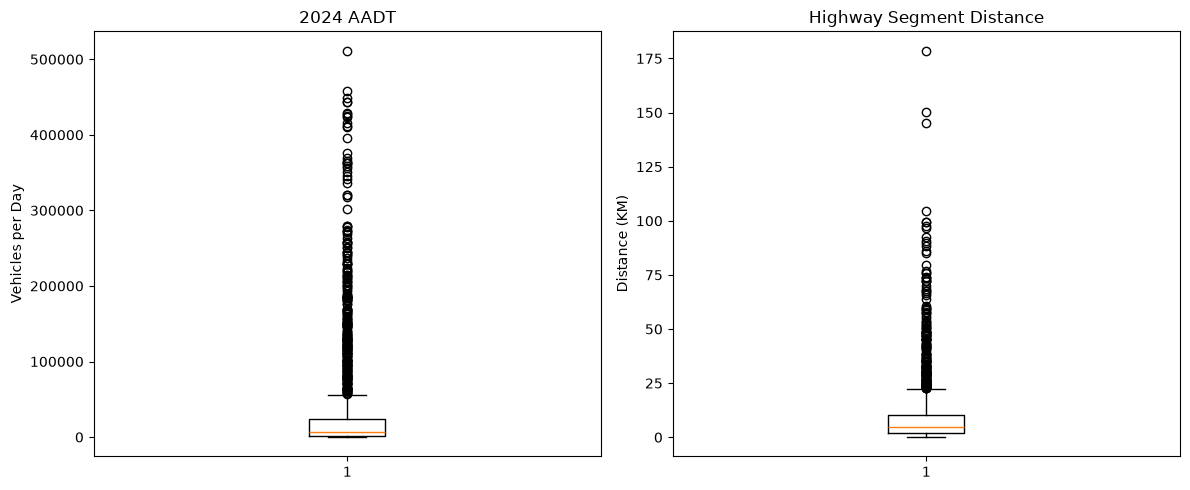

In [3]:
# Create two boxplots to examine the original numerical variables
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Boxplot for annual average daily traffic
axes[0].boxplot(df["2024 AADT"].dropna())
axes[0].set_title("2024 AADT")
axes[0].set_ylabel("Vehicles per Day")

# Boxplot for highway segment distance
axes[1].boxplot(df["Distance (KM)"].dropna())
axes[1].set_title("Highway Segment Distance")
axes[1].set_ylabel("Distance (KM)")

# Adjust spacing and display the plots
plt.tight_layout()
plt.show()


### 1.3 Initial Data Exploration Findings

The dataset contains 2,712 rows and five columns. Of these, 611 rows have missing distance values and 902 have missing AADT values.

Both numerical variables show right-skewed distributions with many potential outliers.

For AADT, the mean is approximately 31,808 vehicles per day, while the median is only 7,350. This indicates that a relatively small number of highway segments have much higher traffic volumes than most others.

Similarly, the average segment distance is approximately 9.12 km, compared with a median of 4.74 km. Some segments are considerably longer than others.

We will not automatically remove the potential outliers because they may represent genuine highway characteristics. However, we will need to standardize the variables before clustering because their numerical scales are very different.

We will also need to address missing values, since K-means requires complete numerical observations for the selected clustering variables.

## 2. Data Cleaning

Before performing K-means clustering, we need to prepare a dataset containing valid observations for both selected numerical variables.

We will remove rows with missing AADT or distance values because both measurements are required to calculate similarities between highway segments.

We will also exclude zero or negative values, since highway segment distances and traffic volumes should be positive.

We will retain valid high values rather than automatically removing outliers, as these may represent important differences in highway traffic conditions.

The original dataset will remain unchanged, and the cleaned data will be stored separately.

In [4]:
# Create a separate copy of the dataset for clustering
df_clean = df.copy()

# Remove rows with missing values in either clustering variable
df_clean = df_clean.dropna(
    subset=["Distance (KM)", "2024 AADT"]
)

# Keep only positive distance and AADT values
df_clean = df_clean[
    (df_clean["Distance (KM)"] > 0) &
    (df_clean["2024 AADT"] > 0)
].copy()

# Display how many rows remain after cleaning
print("Original number of rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

# Confirm that the selected variables have no missing values
print("\nRemaining missing values:")
print(df_clean[["Distance (KM)", "2024 AADT"]].isnull().sum())

# Display the first five cleaned rows
df_clean.head()


Original number of rows: 2712
Rows after cleaning: 1810
Rows removed: 902

Remaining missing values:
Distance (KM)    0
2024 AADT        0
dtype: int64


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


### 2.1 Data Cleaning Results

After cleaning, 1,810 of the original 2,712 observations remain, representing approximately 66.7% of the dataset.

A total of 902 rows (33.3%) were excluded because they did not meet the requirements for clustering.

The cleaned dataset contains no missing values in either AADT or distance. All remaining values are positive.

We will use these 1,810 highway segments for the clustering analysis. Since some observations were excluded, our findings will describe the segments with complete measurements rather than every segment in the original dataset.

## 3. Selecting Variables for K-Means Clustering

We have selected two numerical variables to define our clusters:

1. **2024 AADT (Annual Average Daily Traffic):** Represents the average number of vehicles travelling along a highway segment per day. This helps us distinguish between segments with low and high traffic demand.

2. **Distance (KM):** Represents the length of each highway segment. This helps us distinguish between shorter and longer road segments.

We selected these variables because they describe two different characteristics of Ontario's highways and are both available in our cleaned dataset.

By clustering highway segments using these variables, we hope to identify groups with similar traffic volumes and segment lengths. For example, we may find short segments with high traffic volumes or longer segments with lower traffic volumes.

These patterns can help us better understand differences in traffic demand across Ontario's highway network.

However, AADT and segment distance do not directly measure congestion or travel delays. Therefore, we will interpret our clusters as groups with similar traffic characteristics rather than confirmed congestion levels.

In [5]:

# Select the two numerical variables for clustering
cluster_data = df_clean[["Distance (KM)", "2024 AADT"]].copy()

# Display the first five rows
cluster_data.head()

,Distance (KM),2024 AADT
0,0.230,13400.0
1,0.933,19100.0
2,1.045,18300.0
3,2.450,22600.0
4,2.059,26300.0


### 3.1 Standardizing the Data

Before applying K-means clustering, we need to standardize our two numerical variables because they are measured on very different scales.

AADT measures thousands of vehicles per day, while distance is measured in kilometres. Without standardization, AADT would have a much greater influence on the distance calculations used by K-means.

We will use **Z-score standardization**, one of the methods demonstrated in class.

Z-score standardization subtracts the mean of each variable and divides by its standard deviation. This produces variables with a mean of approximately 0 and a standard deviation of approximately 1.

We chose this method because it allows AADT and distance to contribute on comparable numerical scales when forming clusters.

Standardization does not remove outliers or change the overall shape of the distributions.

In [6]:
# Define the Z-score standardization function from class
def stamn(x):
    return (x - x.mean()) / x.std()

# Standardize both clustering variables
cluster_scaled = cluster_data.apply(stamn)

# Display the first five standardized observations
print("Standardized Data:")
display(cluster_scaled.head())

# Check the means and standard deviations
print("\nMeans after standardization:")
print(cluster_scaled.mean().round(4))

print("\nStandard deviations after standardization:")
print(cluster_scaled.std().round(4))


Standardized Data:


,Distance (KM),2024 AADT
0,-0.714767,-0.275936
1,-0.658392,-0.190494
2,-0.649410,-0.202486
3,-0.536740,-0.138030
4,-0.568095,-0.082568



Means after standardization:
Distance (KM)    0.0
2024 AADT        0.0
dtype: float64

Standard deviations after standardization:
Distance (KM)    1.0
2024 AADT        1.0
dtype: float64


## 4. Determining the Number of Clusters

K-means clustering requires us to specify the number of clusters, represented by **k**.

To help determine an appropriate value of k, we will use the elbow method demonstrated in class.

The elbow method involves running K-means with different numbers of clusters and calculating the within-cluster sum of squares (WCSS) for each model.

WCSS measures how closely observations are grouped around their assigned cluster centres. Lower values indicate more compact clusters, but WCSS naturally decreases as more clusters are added.

We will examine the elbow chart to identify where the improvement begins to slow down. We will also compare scatterplots and cluster sizes before making our final decision.

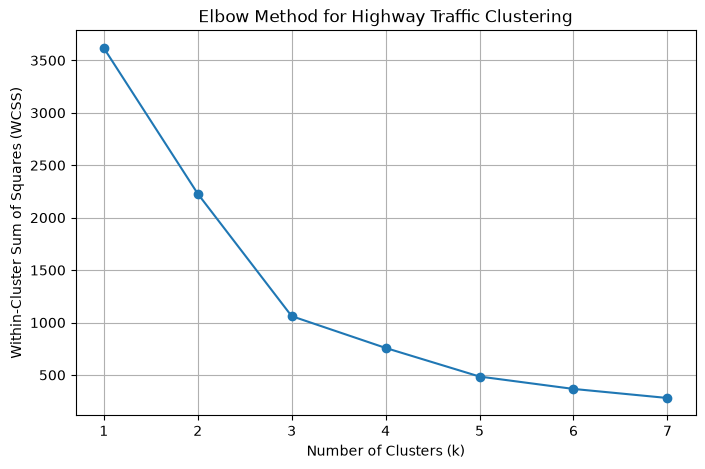

In [7]:
# Create a list to store the within-cluster sum of squares
wcss = []

# Test K-means models with 1 through 7 clusters
for k in range(1, 8):

    # Create and fit the K-means model
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(cluster_scaled)

    # Store the within-cluster sum of squares
    wcss.append(model.inertia_)

# Plot the elbow chart
plt.figure(figsize=(8, 5))
plt.plot(range(1, 8), wcss, marker="o")

plt.title("Elbow Method for Highway Traffic Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.xticks(range(1, 8))
plt.grid(True)

plt.show()


### 4.1 Elbow Method Results

The elbow chart shows a substantial decrease in within-cluster sum of squares (WCSS) as the number of clusters increases from 1 to 3.

After k = 3, the curve begins to flatten, meaning that adding more clusters produces smaller improvements in compactness.

Based on this pattern, **k = 3 appears to be a reasonable candidate** for our highway traffic dataset.

However, the elbow method alone does not guarantee the best clustering solution. We will also examine cluster sizes and scatterplots for k = 3, 4, and 5 before selecting the final number of clusters.

### 4.2 Comparing Candidate Cluster Solutions

To further evaluate the number of clusters, we will compare K-means solutions using 3, 4, and 5 clusters.

We will examine scatterplots to see how the observations are divided and compare cluster sizes to identify whether any clusters contain very few highway segments.

This will help us determine whether additional clusters reveal meaningful traffic patterns or simply divide existing groups into smaller categories.


Cluster sizes for k = 3:
0    1529
1     165
2     116
Name: count, dtype: int64

Cluster sizes for k = 4:
0    1282
1     160
2      67
3     301
Name: count, dtype: int64

Cluster sizes for k = 5:
0    1255
1      48
2      66
3     173
4     268
Name: count, dtype: int64


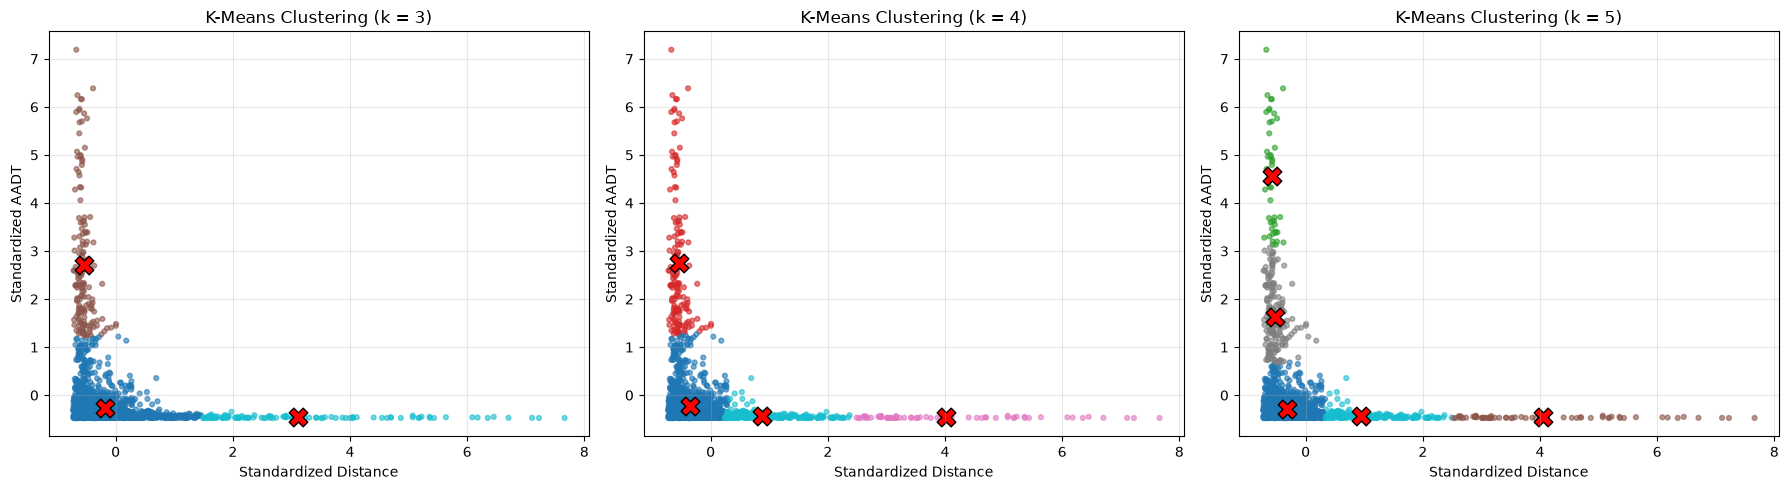

In [8]:
# Compare K-means clustering results for k = 3, 4, and 5
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, [3, 4, 5]):

    # Fit the K-means model
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(cluster_scaled)

    # Plot the highway segments using standardized values
    ax.scatter(
        cluster_scaled["Distance (KM)"],
        cluster_scaled["2024 AADT"],
        c=labels,
        cmap="tab10",
        s=12,
        alpha=0.6
    )

    # Mark the cluster centres
    ax.scatter(
        model.cluster_centers_[:, 0],
        model.cluster_centers_[:, 1],
        c="red",
        marker="X",
        s=180,
        edgecolors="black"
    )

    ax.set_title(f"K-Means Clustering (k = {k})")
    ax.set_xlabel("Standardized Distance")
    ax.set_ylabel("Standardized AADT")
    ax.grid(True, alpha=0.3)

    # Display the number of segments in each cluster
    print(f"\nCluster sizes for k = {k}:")
    print(pd.Series(labels).value_counts().sort_index())

plt.tight_layout()
plt.show()


### 4.3 Selecting the Final Number of Clusters

After examining the elbow chart, scatterplots, and cluster sizes, we selected **k = 3** for our final K-means model.

The elbow chart shows a noticeable bend at k = 3, suggesting that additional clusters provide smaller improvements in within-cluster sum of squares.

The scatterplots also show three broad patterns: a large group of relatively short, lower-volume highway segments, a smaller group with higher traffic volumes, and another group with longer segment distances.

With k = 3, the cluster sizes are 1,529, 165, and 116 observations. Although the groups are uneven, they represent meaningful differences in the two variables.

The k = 4 and k = 5 solutions divide these broader groups into smaller categories. For this analysis, we chose k = 3 because it provides a simpler and more interpretable summary of the highway dataset.

We recognize that the large size of the main cluster and the presence of extreme values are limitations of this solution.

## 5. Final K-Means Clustering Model

Based on our evaluation, we will use three clusters for the final analysis.

We will apply K-means to the standardized AADT and distance variables and assign each highway segment to a cluster.

The cluster assignments will be added to the cleaned dataset so we can examine the original traffic volumes, distances, and highway information for each group.

We will use the original units when interpreting the clusters because vehicles per day and kilometres are easier to understand than standardized values.

In [9]:

# Create the final K-means model with three clusters
final_model = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and assign each segment to a cluster
final_labels = final_model.fit_predict(cluster_scaled)

# Add the cluster assignments to the cleaned dataset
df_clean["Cluster"] = final_labels

# Display the number of segments in each cluster
print("Final Cluster Sizes:")
print(df_clean["Cluster"].value_counts().sort_index())

# Display the first five rows with cluster assignments
df_clean.head()


Final Cluster Sizes:
Cluster
0    1529
1     165
2     116
Name: count, dtype: int64


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT,Cluster
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0,0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0,0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0,0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0,0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0,0


### 5.1 Cluster Summary

After assigning each highway segment to a cluster, we will summarize the characteristics of each group.

We will calculate the number of segments, average and median AADT, and average and median distance for each cluster.

These statistics will help us understand how the clusters differ and allow us to assign meaningful descriptive names.

We will use the original measurements rather than standardized values so that the results can be interpreted in vehicles per day and kilometres.

In [10]:
# Summarize the original AADT and distance values for each cluster
cluster_summary = df_clean.groupby("Cluster").agg(
    Segments=("2024 AADT", "count"),
    Mean_AADT=("2024 AADT", "mean"),
    Median_AADT=("2024 AADT", "median"),
    Mean_Distance_KM=("Distance (KM)", "mean"),
    Median_Distance_KM=("Distance (KM)", "median")
)

# Calculate the percentage of highway segments in each cluster
cluster_summary["Percentage"] = (
    cluster_summary["Segments"] / len(df_clean) * 100
)

# Round the results for easier reading
cluster_summary = cluster_summary.round(2)

# Display the cluster summary table
display(cluster_summary)


,Segments,Mean_AADT,Median_AADT,Mean_Distance_KM,Median_Distance_KM,Percentage
Cluster,,,,,,
0,1529,14625.32,7000.0,6.94,5.20,84.48
1,165,212658.18,184200.0,2.35,2.04,9.12
2,116,1054.66,550.0,47.91,44.06,6.41


### 5.2 Cluster Names and Interpretation

Based on the cluster summary statistics, we assigned the following descriptive names:

**Cluster 0 — Short-to-Medium, Moderate-Volume Segments**

- Contains 1,529 highway segments (84.48% of the cleaned dataset).
- Average AADT: approximately 14,625 vehicles per day.
- Average segment distance: 6.94 km.

This is the largest cluster and represents the majority of highway segments in our analysis. These segments generally have shorter-to-medium distances and much lower traffic volumes than the high-volume cluster.

**Cluster 1 — Short, High-Volume Segments**

- Contains 165 highway segments (9.12% of the cleaned dataset).
- Average AADT: approximately 212,658 vehicles per day.
- Average segment distance: 2.35 km.

This cluster contains the segments with the highest traffic volumes and relatively short distances. These locations may be useful candidates for further congestion investigation because they experience high traffic demand. However, AADT alone cannot confirm whether congestion occurs.

**Cluster 2 — Long, Low-Volume Segments**

- Contains 116 highway segments (6.41% of the cleaned dataset).
- Average AADT: approximately 1,055 vehicles per day.
- Average segment distance: 47.91 km.

This cluster contains much longer highway segments with relatively low traffic volumes. These segments have substantially different characteristics from the short, high-volume segments in Cluster 1.

### 5.3 Insights from Clustering

K-means clustering helped us identify three distinct traffic and road-segment patterns within Ontario's provincial highway dataset.

The majority of segments belong to the short-to-medium, moderate-volume group. However, a smaller group of segments carries substantially higher daily traffic volumes, while another group consists of long segments with very low traffic volumes.

These findings show that Ontario highway segments vary considerably in both traffic demand and segment length.

For our highway congestion project, Cluster 1 may be particularly useful for identifying segments that deserve further investigation. Additional information, such as traffic speeds, road capacity, and travel delays, would be needed to determine whether these segments actually experience congestion.

Overall, clustering provided a way to examine differences across the highway network rather than relying only on overall averages.

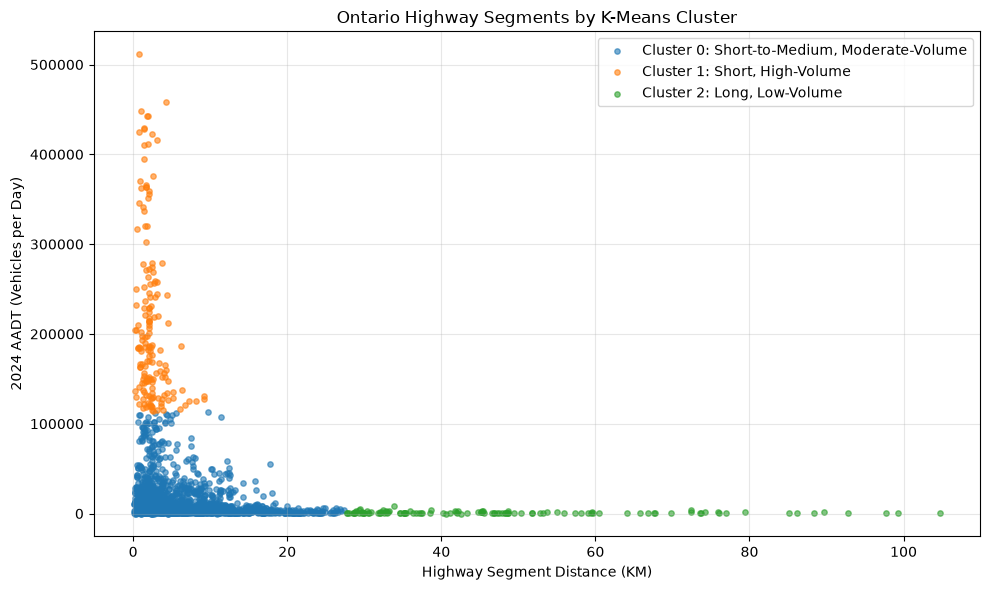

In [11]:
# Define descriptive names for the three clusters
cluster_names = {
    0: "Short-to-Medium, Moderate-Volume",
    1: "Short, High-Volume",
    2: "Long, Low-Volume"
}

# Create a scatterplot of the final clusters
plt.figure(figsize=(10, 6))

for cluster_id, name in cluster_names.items():

    # Select highway segments belonging to this cluster
    subset = df_clean[df_clean["Cluster"] == cluster_id]

    # Plot distance against original AADT values
    plt.scatter(
        subset["Distance (KM)"],
        subset["2024 AADT"],
        label=f"Cluster {cluster_id}: {name}",
        s=15,
        alpha=0.6
    )

# Label the chart
plt.title("Ontario Highway Segments by K-Means Cluster")
plt.xlabel("Highway Segment Distance (KM)")
plt.ylabel("2024 AADT (Vehicles per Day)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### 5.4 Final Cluster Visualization

The final scatterplot illustrates the three groups identified by K-means using the original AADT and distance measurements.

Cluster 0 contains most highway segments, which generally have shorter-to-medium distances and lower-to-moderate traffic volumes.

Cluster 1 contains relatively short segments with substantially higher traffic volumes, making this group particularly relevant to our investigation of highway traffic demand.

Cluster 2 contains longer highway segments with comparatively low traffic volumes.

The separation between these groups supports our interpretation of the clusters. However, the clustering reflects similarities in AADT and segment distance rather than directly measured congestion levels.

### 5.5 Highway Distribution Across Clusters

To connect our clustering results to the original highway congestion project, we will examine which Ontario highways appear most frequently in each cluster.

We will count the number of segments belonging to each highway within each cluster and display the five most frequently represented highways.

This will help us identify which highways contribute most to the different traffic patterns.

However, the results represent the number of recorded highway segments, not the total length of each highway or its overall congestion level.

In [12]:
# Count how many segments each highway has in each cluster
highway_counts = (
    df_clean.groupby(["Cluster", "Highway"])
    .size()
    .reset_index(name="Segments")
)

# Display the five most frequently represented highways per cluster
for cluster_id in sorted(df_clean["Cluster"].unique()):

    print(f"\nCluster {cluster_id}: {cluster_names[cluster_id]}")

    # Select and rank highways in this cluster
    top_highways = (
        highway_counts[highway_counts["Cluster"] == cluster_id]
        .sort_values("Segments", ascending=False)
        .head(5)
    )

    # Display the highway numbers and segment counts
    display(top_highways[["Highway", "Segments"]])



Cluster 0: Short-to-Medium, Moderate-Volume


,Highway,Segments
9,11,131
13,17,118
67,401,106
5,7,87
4,6,55



Cluster 1: Short, High-Volume


,Highway,Segments
248,401,53
255,QEW,34
253,417,17
247,400,16
249,403,12



Cluster 2: Long, Low-Volume


,Highway,Segments
258,11,16
259,17,14
267,101,6
276,527,4
291,599,4


### 5.6 Interpretation of Highway Distribution

Examining the highway numbers within each cluster provides additional insight into how traffic characteristics vary across Ontario's provincial highways.

**Cluster 0 — Short-to-Medium, Moderate-Volume Segments**

The most frequently represented highways are Highway 11 (131 segments), Highway 17 (118 segments), and Highway 401 (106 segments).

This shows that the largest cluster includes segments from several different highways rather than being associated with only one route.

**Cluster 1 — Short, High-Volume Segments**

Highway 401 has the most segments in this cluster (53), followed by the QEW (34), Highway 417 (17), and Highway 400 (16).

This is particularly relevant to our project because Highways 401 and 400 were examined in Workshop A. Both highways have segments in the high-volume cluster, with Highway 401 appearing more frequently.

These results suggest that parts of these highways experience high traffic demand and may be useful candidates for further congestion investigation.

**Cluster 2 — Long, Low-Volume Segments**

Highway 11 (16 segments) and Highway 17 (14 segments) appear most frequently in this cluster.

This shows that some segments of these highways are much longer and have lower traffic volumes than the high-volume segments identified in Cluster 1.

### Connection to Workshop A

In Workshop A, we compared traffic volumes on Highways 401 and 400 using statistical hypothesis tests.

Workshop B extends that analysis by examining highway segments across Ontario and identifying groups with similar traffic volumes and distances.

Rather than only comparing average traffic volumes between two highways, K-means clustering allows us to identify different traffic patterns within the broader highway network.

However, these results describe the number of recorded segments in each cluster. They do not establish the overall congestion level of an entire highway.

## 6. Conclusion and Limitations

### Conclusion

In this workshop, we applied K-means clustering to Ontario's 2024 Annual Average Daily Traffic (AADT) dataset to identify groups of highway segments with similar traffic characteristics.

After cleaning the dataset, 1,810 highway segments remained for analysis. We selected AADT and segment distance as our two clustering variables and standardized them using the Z-score method demonstrated in class.

We used the elbow method, scatterplots, and cluster-size comparisons to evaluate different numbers of clusters. Based on these assessments, we selected **k = 3**.

The final model identified three groups:

1. **Short-to-Medium, Moderate-Volume Segments:** The largest group, containing 84.48% of the cleaned dataset.
2. **Short, High-Volume Segments:** A smaller group containing 9.12% of segments, with an average AADT of approximately 212,658 vehicles per day.
3. **Long, Low-Volume Segments:** A group containing 6.41% of segments, with an average length of approximately 47.91 km.

These results show that Ontario highway segments differ considerably in both traffic volume and segment length.

For our highway congestion project, the high-volume cluster may help identify segments that deserve further investigation.

### Limitations

There are several limitations to this analysis:

- **Traffic volume is not the same as congestion.** AADT measures average daily traffic, but does not tell us whether vehicles experience delays or reduced speeds.
- **Missing data:** Approximately 33.3% of the original dataset was excluded because of missing values. The clustering results therefore represent only segments with complete measurements.
- **Outliers:** Both AADT and distance contain extreme values that may influence K-means cluster centres.
- **Uneven cluster sizes:** The largest cluster contains 84.48% of observations, so the model provides broad groups rather than equally sized categories.
- **Single-year dataset:** The analysis uses 2024 data only and cannot identify how traffic patterns have changed over time.

### Future Improvements

Future analysis could include traffic speeds, road capacity, travel delays, or additional years of AADT data.

These additional variables could help distinguish high traffic demand from actual congestion and provide a more complete understanding of Ontario's highway network.